In [141]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
battery_ids = list(set(df.index))
battery_ids.sort(key=lambda x: int(x.split('-')[-1]))
print(battery_ids)
materials = list(set(meta["chemistry"]))
print(materials)
material_mapping = {x: t for x,t in zip(materials, range(3))}

labels = list(set(df["degradation_status"]))

df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])

climate_zones = list(set(meta["climate_zone"]))
print(df2)

['BAT-00001', 'BAT-00002', 'BAT-00003', 'BAT-00004', 'BAT-00005', 'BAT-00006', 'BAT-00007', 'BAT-00008', 'BAT-00009', 'BAT-00010', 'BAT-00011', 'BAT-00012', 'BAT-00013', 'BAT-00014', 'BAT-00015', 'BAT-00016', 'BAT-00017', 'BAT-00018', 'BAT-00019', 'BAT-00020', 'BAT-00021', 'BAT-00022', 'BAT-00023', 'BAT-00024', 'BAT-00025', 'BAT-00026', 'BAT-00027', 'BAT-00028', 'BAT-00029', 'BAT-00030', 'BAT-00031', 'BAT-00032', 'BAT-00033', 'BAT-00034', 'BAT-00035', 'BAT-00036', 'BAT-00037', 'BAT-00038', 'BAT-00039', 'BAT-00040', 'BAT-00041', 'BAT-00042', 'BAT-00043', 'BAT-00044', 'BAT-00045', 'BAT-00046', 'BAT-00047', 'BAT-00048', 'BAT-00049', 'BAT-00050', 'BAT-00051', 'BAT-00052', 'BAT-00053', 'BAT-00054', 'BAT-00055', 'BAT-00056', 'BAT-00057', 'BAT-00058', 'BAT-00059', 'BAT-00060', 'BAT-00061', 'BAT-00062', 'BAT-00063', 'BAT-00064', 'BAT-00065', 'BAT-00066', 'BAT-00067', 'BAT-00068', 'BAT-00069', 'BAT-00070', 'BAT-00071', 'BAT-00072', 'BAT-00073', 'BAT-00074', 'BAT-00075', 'BAT-00076', 'BAT-00077'

(200,)
[615 155 174]
[110  36  54]


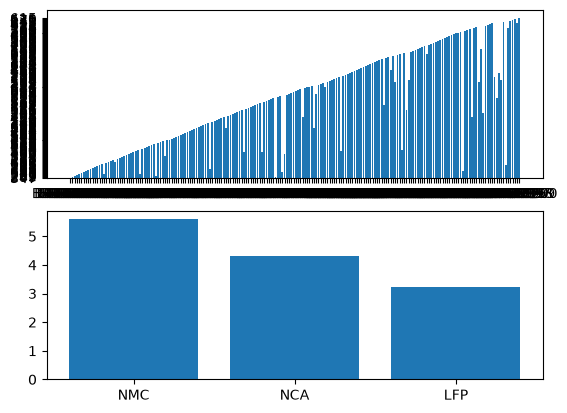

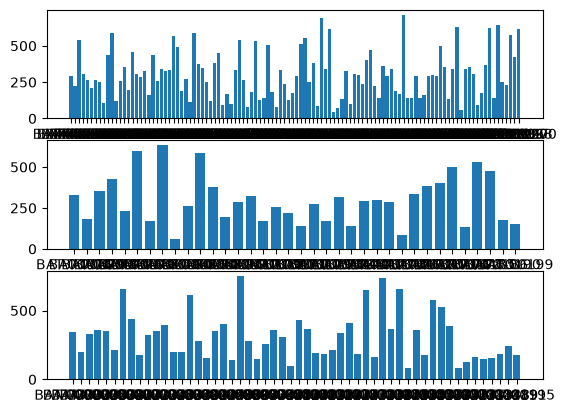

In [ ]:
def find_total_cycles(df, battery_id):
    rel = df[(df.index == battery_id) & (df["degradation_status"] != "Normal")]
    return rel["cycle_index"].min()

values = np.zeros_like(battery_ids)
print(values.shape)
for i,bi in enumerate(battery_ids):
    values[i] = find_total_cycles(df, bi)

values_materials = np.zeros_like(materials, dtype=int)
counts = np.zeros_like(materials, dtype=int)
for k,v in zip(battery_ids, values):
    mat = int(material_mapping[meta.loc[k, "chemistry"]])
    values_materials[mat] = v
    counts[mat] += 1

print(values_materials)
print(counts)

material_counts = np.zeros(len(materials))
mat_labels = []
mat_values = []
for i,m in enumerate(materials):
    material_counts[i] = len(meta[meta["chemistry"] == m])
    x = df[df.index.isin(meta[meta["chemistry"] == m].index)]
    mat_labels.append(x.index.values)
    cur = []
    for item in x.index.values:
        cycle = find_total_cycles(x, item)
        cur.append(cycle)
    mat_values.append(cur)

fig, ax = plt.subplots(2)
fig2, ax2 = plt.subplots(3)
ax[0].bar(battery_ids, values)
ax[1].bar(materials, values_materials / counts)

for i in range(len(materials)):
    ax2[i].bar(mat_labels[i], mat_values[i])


plt.show()
    

climate_zone        Desert    Equatorial   Nordic     Temperate
cycle_index                                                    
1                20.311852     20.551351  19.7834     19.818475
2                40.721481     40.868649  39.5444     39.743220
3                61.138333     61.444595  59.3108     59.617119
4                81.606852     81.735556  79.2246     79.506949
5               102.163585    101.699189  99.1628     99.102069
...                    ...           ...      ...           ...
1496          29043.350000  33571.494444      NaN  32840.273529
1497          29065.176667  33498.773750      NaN  32863.380588
1498          29086.403333  33616.726667      NaN  32886.629412
1499          29107.723333  33640.704444      NaN  32909.831765
1500          29128.996667  33664.814444      NaN  32933.077647

[1500 rows x 4 columns]


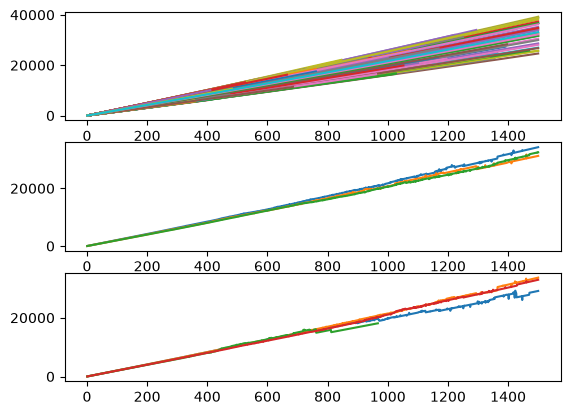

In [ ]:
"""
-internal_resistance_mOhm vs cycle_index
1. plot lines per battery id
2. average across material and zone
"""

fig, ax = plt.subplots(3)
for bi in battery_ids:
    x = df[df.index == bi].sort_values("cycle_index")
    cum_resistance = x["internal_resistance_mOhm"].cumsum().values
    ax[0].plot(x["cycle_index"], cum_resistance)

df2["cum_res"] = df2.groupby("battery_id")["internal_resistance_mOhm"].cumsum()
mean_curves = (
    df2.groupby(["chemistry", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
for mc in mean_curves.columns:
    ax[1].plot(mean_curves.index, mean_curves[mc])

mean_curves = (
    df2.groupby(["climate_zone", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
print(mean_curves)
for mc in mean_curves.columns:
    ax[2].plot(mean_curves.index, mean_curves[mc])

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
battery_ids = list(set(df.index))
battery_ids.sort(key=lambda x: int(x.split('-')[-1]))
print(battery_ids)
materials = list(set(meta["chemistry"]))
print(materials)
material_mapping = {x: t for x,t in zip(materials, range(3))}

['BAT-00001', 'BAT-00002', 'BAT-00003', 'BAT-00004', 'BAT-00005', 'BAT-00006', 'BAT-00007', 'BAT-00008', 'BAT-00009', 'BAT-00010', 'BAT-00011', 'BAT-00012', 'BAT-00013', 'BAT-00014', 'BAT-00015', 'BAT-00016', 'BAT-00017', 'BAT-00018', 'BAT-00019', 'BAT-00020', 'BAT-00021', 'BAT-00022', 'BAT-00023', 'BAT-00024', 'BAT-00025', 'BAT-00026', 'BAT-00027', 'BAT-00028', 'BAT-00029', 'BAT-00030', 'BAT-00031', 'BAT-00032', 'BAT-00033', 'BAT-00034', 'BAT-00035', 'BAT-00036', 'BAT-00037', 'BAT-00038', 'BAT-00039', 'BAT-00040', 'BAT-00041', 'BAT-00042', 'BAT-00043', 'BAT-00044', 'BAT-00045', 'BAT-00046', 'BAT-00047', 'BAT-00048', 'BAT-00049', 'BAT-00050', 'BAT-00051', 'BAT-00052', 'BAT-00053', 'BAT-00054', 'BAT-00055', 'BAT-00056', 'BAT-00057', 'BAT-00058', 'BAT-00059', 'BAT-00060', 'BAT-00061', 'BAT-00062', 'BAT-00063', 'BAT-00064', 'BAT-00065', 'BAT-00066', 'BAT-00067', 'BAT-00068', 'BAT-00069', 'BAT-00070', 'BAT-00071', 'BAT-00072', 'BAT-00073', 'BAT-00074', 'BAT-00075', 'BAT-00076', 'BAT-00077'

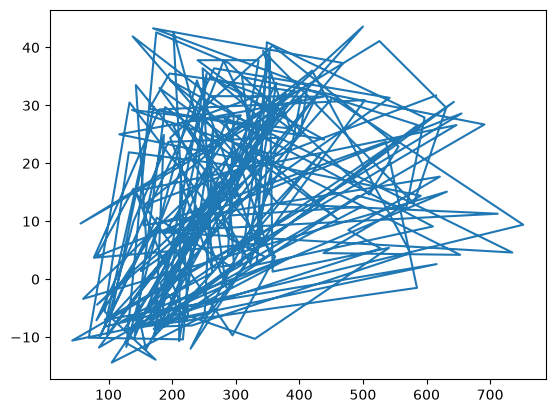

In [85]:
"""
-visualize correlation between pack/ambient heat/temperature and time till failure: eg. xaxis = pack/ambient temp,
yaxis = cycle index or battery_age_days. plot per battery, not per row.
"""

cycle_indices = []
temps = []
for bi in battery_ids:
    x = df[(df["degradation_status"] != "Normal") & (df.index == bi)]
    # first row has lowest cycle_index
    cycle_indices.append(x.iloc[0]["cycle_index"])
    temps.append(x.iloc[0]["ambient_temp_c"])

fig, ax = plt.subplots()
ax.plot(cycle_indices, temps)
plt.show()




       battery_id  cycle_index  pack_temp_c
0       BAT-00001          347          4.2
678     BAT-00002          289          7.2
1132    BAT-00003          202         43.0
1537    BAT-00004          225         -6.0
2050    BAT-00005          330        -10.0
...           ...          ...          ...
108885  BAT-00196          231         -8.0
109338  BAT-00197          575          4.6
110262  BAT-00198          420         36.0
111008  BAT-00199          155         14.8
111335  BAT-00200          615         32.4

[200 rows x 3 columns]
       battery_id                      timestamp  cycle_index  \
678     BAT-00002  2023-11-25 20:24:09.485685816          289   
1537    BAT-00004  2023-03-02 04:36:41.409369744          225   
2686    BAT-00006  2025-03-26 01:15:53.134695776          541   
5023    BAT-00009  2024-02-18 09:27:30.997131672          309   
5636    BAT-00010  2024-02-10 02:56:16.236726888          263   
...           ...                            ...          

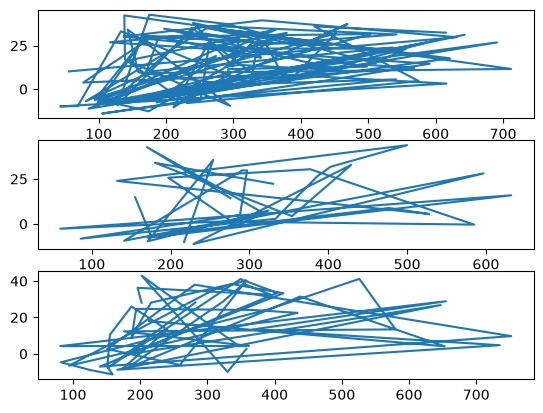

In [100]:
def k(s):
    if s.name == "battery_id":
        return s.str.split("-").str[-1].astype(int)  # "battery-12" -> 12
    return s

eol = (
    df2[df2["degradation_status"] != "Normal"]
    .reset_index()                                    # battery_id becomes a column
    .sort_values(["battery_id", "cycle_index"], key=k)
    .drop_duplicates(subset="battery_id", keep="first")
)

print(eol[["battery_id", "cycle_index", "pack_temp_c"]])

fig, ax = plt.subplots(3)
for i,m in enumerate(materials):
    x = eol[eol["battery_id"].isin(meta[meta["chemistry"] == m].index)]
    print(x)
    ax[i].plot(x["cycle_index"], x["pack_temp_c"])

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
battery_ids = list(set(df.index))
battery_ids.sort(key=lambda x: int(x.split('-')[-1]))
print(battery_ids)
materials = list(set(meta["chemistry"]))
print(materials)
material_mapping = {x: t for x,t in zip(materials, range(3))}

['BAT-00001', 'BAT-00002', 'BAT-00003', 'BAT-00004', 'BAT-00005', 'BAT-00006', 'BAT-00007', 'BAT-00008', 'BAT-00009', 'BAT-00010', 'BAT-00011', 'BAT-00012', 'BAT-00013', 'BAT-00014', 'BAT-00015', 'BAT-00016', 'BAT-00017', 'BAT-00018', 'BAT-00019', 'BAT-00020', 'BAT-00021', 'BAT-00022', 'BAT-00023', 'BAT-00024', 'BAT-00025', 'BAT-00026', 'BAT-00027', 'BAT-00028', 'BAT-00029', 'BAT-00030', 'BAT-00031', 'BAT-00032', 'BAT-00033', 'BAT-00034', 'BAT-00035', 'BAT-00036', 'BAT-00037', 'BAT-00038', 'BAT-00039', 'BAT-00040', 'BAT-00041', 'BAT-00042', 'BAT-00043', 'BAT-00044', 'BAT-00045', 'BAT-00046', 'BAT-00047', 'BAT-00048', 'BAT-00049', 'BAT-00050', 'BAT-00051', 'BAT-00052', 'BAT-00053', 'BAT-00054', 'BAT-00055', 'BAT-00056', 'BAT-00057', 'BAT-00058', 'BAT-00059', 'BAT-00060', 'BAT-00061', 'BAT-00062', 'BAT-00063', 'BAT-00064', 'BAT-00065', 'BAT-00066', 'BAT-00067', 'BAT-00068', 'BAT-00069', 'BAT-00070', 'BAT-00071', 'BAT-00072', 'BAT-00073', 'BAT-00074', 'BAT-00075', 'BAT-00076', 'BAT-00077'

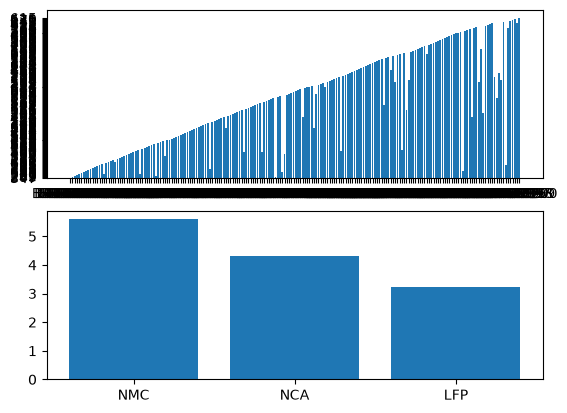

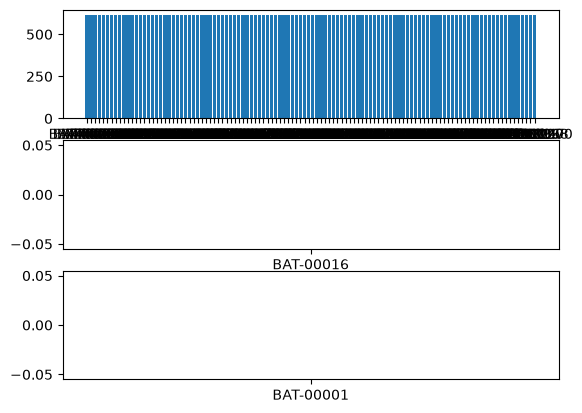

In [151]:
values = np.zeros_like(battery_ids)
for i,bi in enumerate(battery_ids):
    rel = df2[(df2.index == bi) & (df2["degradation_status"] != "Normal")]
    values[i] = rel["cycle_index"].min()

values_materials = np.zeros_like(materials, dtype=int)
material_mapping = {x: t for x,t in zip(materials, range(3))}
counts = np.zeros_like(materials, dtype=int)
for k,v in zip(battery_ids, values):
    mat = int(material_mapping[meta.loc[k, "chemistry"]])
    values_materials[mat] = v
    counts[mat] += 1

material_counts = np.zeros(len(materials))
mat_labels = []
mat_values = []
for i,m in enumerate(materials):
    material_counts[i] = len(meta[meta["chemistry"] == m])
    x = df[df.index.isin(meta[meta["chemistry"] == m].index)]
    mat_labels.append(x.index.values)
    cur = []
    for item in x.index.values:
        rel = x[(x.index == bi) & (x["degradation_status"] != "Normal")]
        cycle = rel["cycle_index"].min()
        cur.append(cycle)
    mat_values.append(cur)

fig, ax = plt.subplots(2)
fig2, ax2 = plt.subplots(3)
ax[0].bar(battery_ids, values)
ax[1].bar(materials, values_materials / counts)

for i in range(len(materials)):
    ax2[i].bar(mat_labels[i], mat_values[i])


plt.show()
    

climate_zone        Desert    Equatorial   Nordic     Temperate
cycle_index                                                    
1                20.311852     20.551351  19.7834     19.818475
2                40.721481     40.868649  39.5444     39.743220
3                61.138333     61.444595  59.3108     59.617119
4                81.606852     81.735556  79.2246     79.506949
5               102.163585    101.699189  99.1628     99.102069
...                    ...           ...      ...           ...
1496          29043.350000  33571.494444      NaN  32840.273529
1497          29065.176667  33498.773750      NaN  32863.380588
1498          29086.403333  33616.726667      NaN  32886.629412
1499          29107.723333  33640.704444      NaN  32909.831765
1500          29128.996667  33664.814444      NaN  32933.077647

[1500 rows x 4 columns]


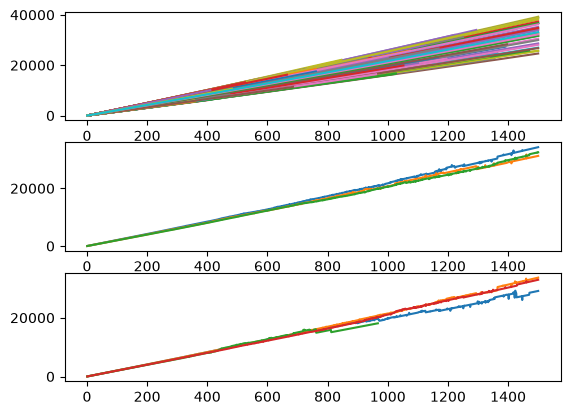

In [ ]:
"""
-internal_resistance_mOhm vs cycle_index
1. plot lines per battery id
2. average across material and zone
"""

fig, ax = plt.subplots(3)
for bi in battery_ids:
    x = df[df.index == bi].sort_values("cycle_index")
    cum_resistance = x["internal_resistance_mOhm"].cumsum().values
    ax[0].plot(x["cycle_index"], cum_resistance)

df2["cum_res"] = df2.groupby("battery_id")["internal_resistance_mOhm"].cumsum()
mean_curves = (
    df2.groupby(["chemistry", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
for mc in mean_curves.columns:
    ax[1].plot(mean_curves.index, mean_curves[mc])

mean_curves = (
    df2.groupby(["climate_zone", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
print(mean_curves)
for mc in mean_curves.columns:
    ax[2].plot(mean_curves.index, mean_curves[mc])

plt.show()

climate_zone        Desert    Equatorial     Nordic     Temperate
cycle_index                                                      
1                24.137037     28.285714   6.970000     15.096610
2                48.233333     55.310811  13.297959     29.796552
3                72.703774     84.235135  19.826531     44.525424
4                96.537037    113.548571  27.208333     59.732203
5               119.232075    140.627027  32.147917     75.489474
...                    ...           ...        ...           ...
1496          36868.700000  41602.444444        NaN  22320.931250
1497          36899.566667  41622.687500        NaN  22360.141176
1498          36932.133333  41655.511111        NaN  22374.094118
1499          36961.200000  41684.311111        NaN  22388.217647
1500          36993.033333  41711.933333        NaN  22402.135294

[1500 rows x 4 columns]


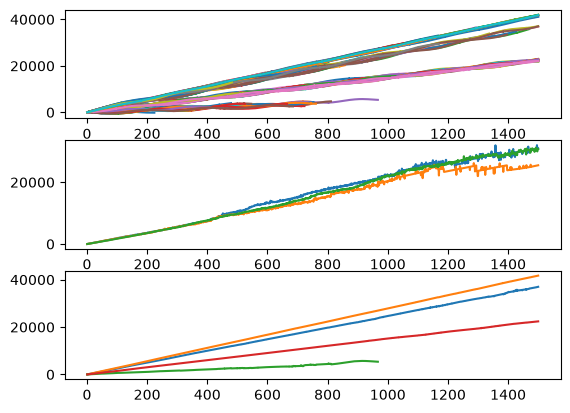

In [101]:
"""
-pack temp vs cycle_index
1. plot lines per battery id
2. average across material and zone
"""

fig, ax = plt.subplots(3)
for bi in battery_ids:
    x = df[df.index == bi].sort_values("cycle_index")
    cum_resistance = x["pack_temp_c"].cumsum().values
    ax[0].plot(x["cycle_index"], cum_resistance)

df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])

df2["cum_res"] = df2.groupby("battery_id")["pack_temp_c"].cumsum()
mean_curves = (
    df2.groupby(["chemistry", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
for mc in mean_curves.columns:
    ax[1].plot(mean_curves.index, mean_curves[mc])

mean_curves = (
    df2.groupby(["climate_zone", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
print(mean_curves)
for mc in mean_curves.columns:
    ax[2].plot(mean_curves.index, mean_curves[mc])

plt.show()

climate_zone        Desert    Equatorial  Nordic     Temperate
cycle_index                                                   
1                23.594444     27.948649   6.536     14.710169
2                47.087037     55.981081  12.878     29.401695
3                70.705556     84.386486  19.184     43.676271
4                94.614815    112.830556  25.930     58.423729
5               116.673585    140.640541  32.118     72.812069
...                    ...           ...     ...           ...
1496          36934.300000  41617.755556     NaN  22205.929412
1497          36965.200000  41653.187500     NaN  22219.782353
1498          36997.266667  41670.411111     NaN  22233.535294
1499          37026.100000  41698.866667     NaN  22247.364706
1500          37057.766667  41726.133333     NaN  22261.041176

[1500 rows x 4 columns]


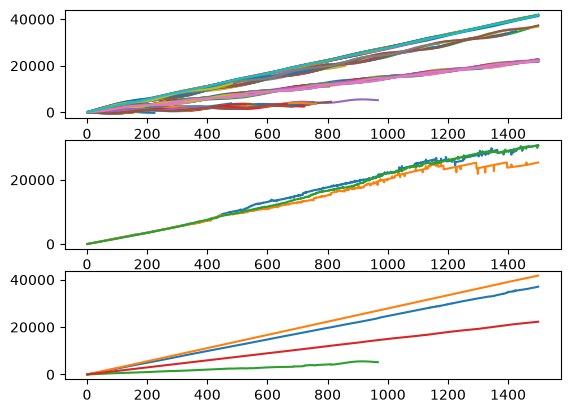

In [102]:
"""
-ambient temp vs cycle_index
1. plot lines per battery id
2. average across material and zone
"""

fig, ax = plt.subplots(3)
for bi in battery_ids:
    x = df[df.index == bi].sort_values("cycle_index")
    cum_resistance = x["ambient_temp_c"].cumsum().values
    ax[0].plot(x["cycle_index"], cum_resistance)

df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])

df2["cum_res"] = df2.groupby("battery_id")["ambient_temp_c"].cumsum()
mean_curves = (
    df2.groupby(["chemistry", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
for mc in mean_curves.columns:
    ax[1].plot(mean_curves.index, mean_curves[mc])

mean_curves = (
    df2.groupby(["climate_zone", "cycle_index"])["cum_res"]
    .mean()
    .unstack(level=0)        # one column per chemistry. in general: level=0 makes the first variable in the index the columns.
)
print(mean_curves)
for mc in mean_curves.columns:
    ax[2].plot(mean_curves.index, mean_curves[mc])

plt.show()

/tmp/ipykernel_8106/3038813184.py:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


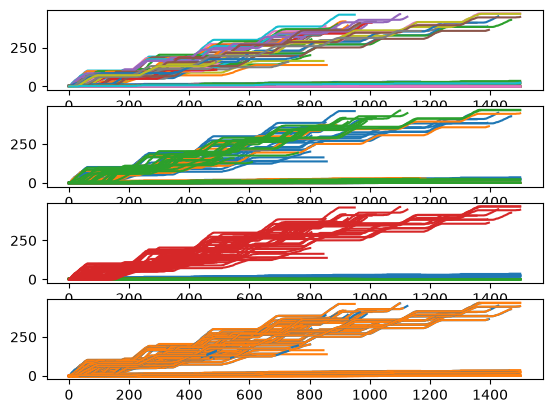

In [139]:
"""
cumulative high temp hours vs. cycle index:
1. all
2. per material group
3. per climate group
"""

fig, ax = plt.subplots(4)
for bi in battery_ids:
    x = df2[df2.index == bi].sort_values("cycle_index")
    ax[0].plot(x["cycle_index"], x["cumulative_high_temp_hours"])

colors = {m: f"C{i}" for i, m in enumerate(materials)}
for i,m in enumerate(materials):
    x = df2[df2["chemistry"] == m]
    for bi in battery_ids:
        y = x[x.index == bi].sort_values("cycle_index")
        ax[1].plot(y["cycle_index"], y["cumulative_high_temp_hours"], color=colors[m])

colors = {m: f"C{i}" for i, m in enumerate(climate_zones)}
for i,m in enumerate(climate_zones):
    x = df2[df2["climate_zone"] == m]
    for bi in battery_ids:
        y = x[x.index == bi].sort_values("cycle_index")
        ax[2].plot(y["cycle_index"], y["cumulative_high_temp_hours"], color=colors[m])

for bi in battery_ids:
    x = df2[df2.index == bi].sort_values("cycle_index")
    x1 = x[x["cooling_active"] == True]
    x2 = x[x["cooling_active"] == False]
    ax[3].plot(x1["cycle_index"], x1["cumulative_high_temp_hours"], color="C0")
    ax[3].plot(x2["cycle_index"], x2["cumulative_high_temp_hours"], color="C1")

fig.show()


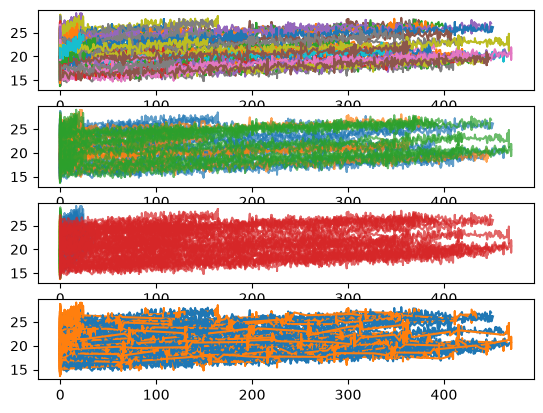

In [138]:
"""
cumulative high temp hours vs. internal resistance
"""

fig, ax = plt.subplots(4)
for bi in battery_ids:
    x = df2[df2.index == bi]
    ax[0].plot(x["cumulative_high_temp_hours"], x["internal_resistance_mOhm"])

colors = {m: f"C{i}" for i, m in enumerate(materials)}
for i,m in enumerate(materials):
    x = df2[df2["chemistry"] == m]
    for bi in battery_ids:
        y = x[x.index == bi]
        ax[1].plot(y["cumulative_high_temp_hours"], y["internal_resistance_mOhm"], color=colors[m], alpha=0.7)

colors = {m: f"C{i}" for i, m in enumerate(climate_zones)}
for i,m in enumerate(climate_zones):
    x = df2[df2["climate_zone"] == m]
    for bi in battery_ids:
        y = x[x.index == bi]
        ax[2].plot(y["cumulative_high_temp_hours"], y["internal_resistance_mOhm"], color=colors[m], alpha=0.7)


colors = ["C0", "C1"]
for bi in battery_ids:
    x = df2[(df2.index == bi)]
    x1 = x[x["cooling_active"] == True]
    x2 = x[x["cooling_active"] == False]
    ax[3].plot(x1["cumulative_high_temp_hours"], x1["internal_resistance_mOhm"], color=colors[0])
    ax[3].plot(x2["cumulative_high_temp_hours"], x2["internal_resistance_mOhm"], color=colors[1])

plt.show()

# df["cum_internal_resist"] = df["internal_resistance_mOhm"].cumsum()
# ax.plot(df["cumulative_high_temp_hours"], df["internal_resistance_mOhm"])
# plt.show()

lables: ['Severe', 'Moderate', 'Critical', 'Normal']


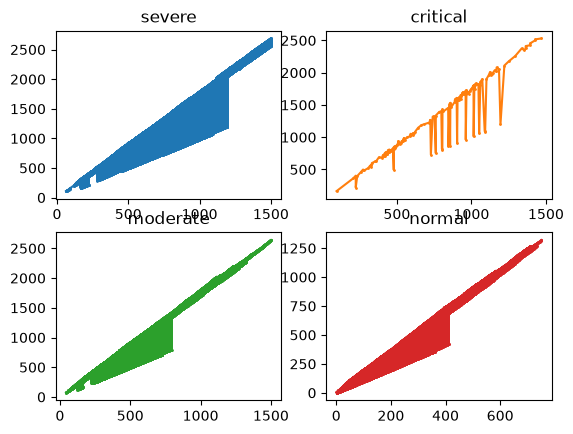

In [ ]:
"""
-per category of degradation, battery age days
"""

fig, ax = plt.subplots(2,2)
colors = [
    ["C0", "C1"],
    ["C2", "C3"]
]
print('lables:', labels)
for i,d in enumerate(labels):
    x = df2[df2["degradation_status"] == d].sort_values("cycle_index")
    j = i%2
    k = i//2
    ax[j,k].plot(x["cycle_index"], x["battery_age_days"], color=colors[j][k], marker="o", markersize=1)

ax[0,0].set_title("severe")
ax[1,0].set_title("moderate")
ax[0,1].set_title("critical")
ax[1,1].set_title("normal")

plt.show()


lables: ['Severe', 'Moderate', 'Critical', 'Normal']


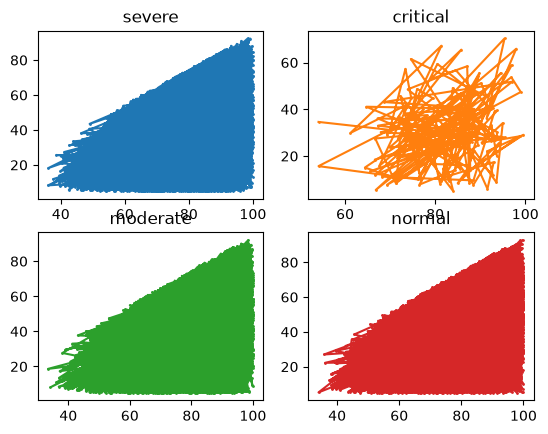

In [152]:
fig, ax = plt.subplots(2,2)
colors = [
    ["C0", "C1"],
    ["C2", "C3"]
]
print('lables:', labels)
for i,d in enumerate(labels):
    x = df2[df2["degradation_status"] == d].sort_values("cycle_index")
    j = i%2
    k = i//2
    ax[j,k].plot(x["soc_start_pct"], x["soc_end_pct"], color=colors[j][k], marker="o", markersize=1)

ax[0,0].set_title("severe")
ax[1,0].set_title("moderate")
ax[0,1].set_title("critical")
ax[1,1].set_title("normal")

plt.show()
    